# Дообучение `deepvk/USER-bge-m3` на банковских документах

Двухэтапный пайплайн:

```
Этап 1 — TSDAE (unsupervised)          Этап 2 — MNRL / TripletLoss (supervised)
────────────────────────────           ─────────────────────────────────────────
data_test/stage1_tsdae/                data_test/stage2_supervised/
  corpus.csv  (75 чанков)                train.csv  (47 триплетов)
                                          eval.csv   (12 триплетов)

Corrupted(text) → Encoder               anchor  → ┐
                       ↓                positive → ├─ Loss → градиент
                  Decoder → text         negative → ┘
```

Оба этапа используют **реальные** тестовые данные из `data_test/`.

In [1]:
!nvidia-smi

Tue Mar 24 18:07:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.02              Driver Version: 560.94         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060        On  |   00000000:01:00.0  On |                  N/A |
|  0%   43C    P8             12W /  170W |     696MiB /  12288MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 0. Окружение

In [2]:
import sys, os, warnings, logging, re
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

from src import EmbeddingTrainer, LossType
from src.trainer import make_cpu_config, make_gpu_config
from src.metrics import RetrievalEvaluator, build_evaluation_set

DATA = Path("../data_test")
OUT  = Path("../output");  OUT.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "deepvk/USER-bge-m3"

print(f"Устройство: {DEVICE}")
print(f"PyTorch: {torch.__version__}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

2026-03-24 18:07:27,791 | INFO | Loading faiss with AVX2 support.
2026-03-24 18:07:27,832 | INFO | Successfully loaded faiss with AVX2 support.


Устройство: cuda
PyTorch: 2.6.0+cu124
GPU: NVIDIA GeForce RTX 3060


---
# ЭТАП 1 — TSDAE: доменная адаптация без разметки

**Идея:** учим модель восстанавливать исходный текст из зашумлённой версии.  
Никаких лейблов не нужно — только сырые чанки из банковских документов.

```
"Льготный период по карте составляет до 55 дней"
         ↓  noise_ratio=0.6 (удаляем ~60% слов)
"период карте 55"
         ↓  Encoder → эмбеддинг
         ↓  Decoder → reconstruct
"Льготный период по карте составляет до 55 дней"  ← цель
```

Модель вынуждена выучить семантику банковских терминов, чтобы восстанавливать текст из 2–3 слов.

## 1.1 Загрузка корпуса

In [3]:
corpus_df = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")

print(f"Чанков в корпусе: {len(corpus_df)}")
print(f"Колонки: {corpus_df.columns.tolist()}\n")

corpus_df["n_words"] = corpus_df["sentence"].str.split().str.len()
corpus_df[["sentence", "n_words"]].head(10)

Чанков в корпусе: 75
Колонки: ['sentence']



,sentence,n_words
0,Ипотечный кредит предоставляется под залог при...,16
1,Первоначальный взнос по ипотеке составляет не ...,15
2,Процентная ставка по ипотеке зависит от размер...,16
3,Государственная программа льготной ипотеки поз...,15
4,Страхование предмета залога от рисков утраты и...,13
5,Досрочное погашение ипотеки осуществляется без...,15
6,Рефинансирование ипотечного кредита позволяет ...,13
7,Материнский капитал может быть использован в к...,16
8,Ипотечные каникулы предоставляются на срок до ...,15
9,Оценка недвижимости для целей ипотечного креди...,11


## 1.2 EDA корпуса

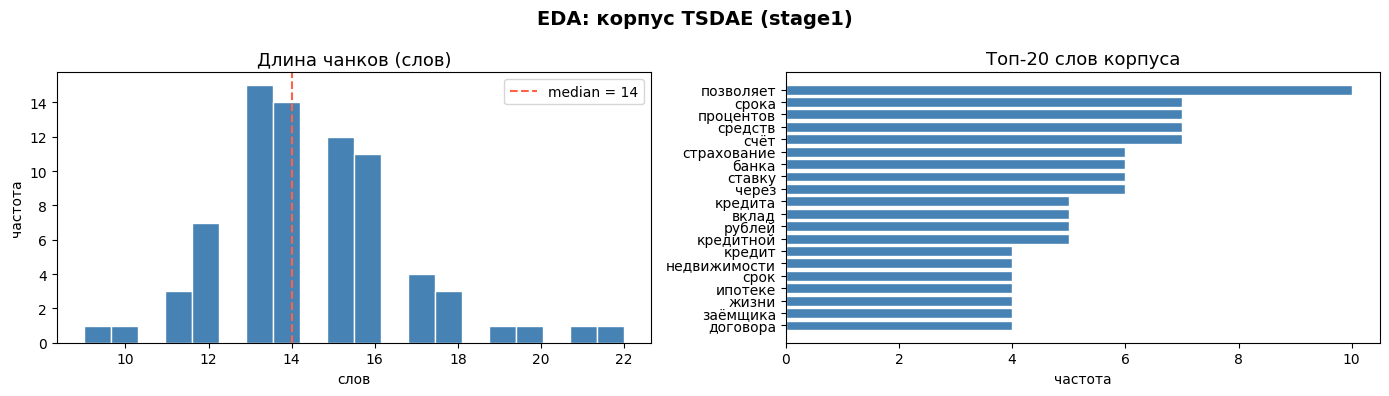


Средняя длина чанка : 14.5 слов
Уникальных слов     : 606


In [4]:
# Распределение длин + топ-слова
from collections import Counter

STOPWORDS = {"и","в","на","по","от","до","или","для","при","не","а",
             "к","с","из","за","как","то","что","это","но","если",
             "о","об","со","под","его","её","их","также","только"}

all_words = [
    w.lower().strip(".,;:—()\"«»") 
    for s in corpus_df["sentence"] 
    for w in s.split() 
    if w.lower().strip(".,;:—()\"«»") not in STOPWORDS and len(w) > 3
]
top_words = Counter(all_words).most_common(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Длины
ax1.hist(corpus_df["n_words"], bins=20, color="steelblue", edgecolor="white")
ax1.axvline(corpus_df["n_words"].median(), color="tomato", linestyle="--",
            label=f'median = {corpus_df["n_words"].median():.0f}')
ax1.set_title("Длина чанков (слов)", fontsize=13)
ax1.set_xlabel("слов"); ax1.set_ylabel("частота")
ax1.legend()

# Топ слова
words, counts = zip(*top_words)
ax2.barh(words[::-1], counts[::-1], color="steelblue", edgecolor="white")
ax2.set_title("Топ-20 слов корпуса", fontsize=13)
ax2.set_xlabel("частота")

plt.suptitle("EDA: корпус TSDAE (stage1)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nСредняя длина чанка : {corpus_df['n_words'].mean():.1f} слов")
print(f"Уникальных слов     : {len(set(all_words))}")

## 1.3 Визуализация процесса шумирования (что именно видит модель)

In [5]:
import random
random.seed(42)

def add_noise(text: str, noise_ratio: float = 0.6) -> str:
    """Удаляем случайные слова — имитируем TSDAE corruption."""
    words = text.split()
    kept = [w for w in words if random.random() > noise_ratio]
    return " ".join(kept) if kept else words[0]

# Показываем на реальных примерах из corpus.csv
sample_sentences = corpus_df["sentence"].sample(6, random_state=42).tolist()

print("Примеры шумирования (noise_ratio = 0.6):\n")
print(f"{'ОРИГИНАЛ':<65}  →  ЗАШУМЛЁННЫЙ ВХОД ДЛЯ МОДЕЛИ")
print("─" * 110)
for s in sample_sentences:
    noised = add_noise(s, noise_ratio=0.6)
    orig_words  = len(s.split())
    kept_words  = len(noised.split())
    print(f"{s[:63]:<65}  →  {noised}")
    print(f"  {'':65}     [{kept_words}/{orig_words} слов оставлено]")
    print()

Примеры шумирования (noise_ratio = 0.6):

ОРИГИНАЛ                                                           →  ЗАШУМЛЁННЫЙ ВХОД ДЛЯ МОДЕЛИ
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
Страхование предмета залога от рисков утраты и повреждения явля    →  Страхование рисков утраты и
                                                                        [4/13 слов оставлено]

Диверсификация портфеля снижает несистематический риск за счёт     →  портфеля за распределения средств классами
                                                                        [5/13 слов оставлено]

Совместные заёмщики по ипотеке несут солидарную ответственность    →  по ипотеке несут солидарную по
                                                                        [5/10 слов оставлено]

Ипотечный кредит предоставляется под залог приобретаемой или им    →  Ипотечный кредит предоставляется залог 1
                                         

In [6]:
# Как noise_ratio влияет на количество оставшихся слов
ratios = [0.3, 0.5, 0.6, 0.7, 0.8]
example = corpus_df["sentence"].iloc[1]  # фиксированный пример

print(f"Пример: \"{example}\"\n")
print(f"{'noise_ratio':<14} {'оставлено слов':<18} {'зашумлённый текст'}")
print("─" * 90)
for r in ratios:
    random.seed(42)
    n = add_noise(example, noise_ratio=r)
    kept = len(n.split())
    total = len(example.split())
    bar = "█" * kept + "░" * (total - kept)
    print(f"{r:<14} {kept}/{total} {bar:<20}  {n}")

Пример: "Первоначальный взнос по ипотеке составляет не менее 15% от стоимости объекта недвижимости при стандартных программах."

noise_ratio    оставлено слов     зашумлённый текст
──────────────────────────────────────────────────────────────────────────────────────────
0.3            7/15 ███████░░░░░░░░       Первоначальный составляет не менее от недвижимости программах.
0.5            6/15 ██████░░░░░░░░░       Первоначальный составляет не менее недвижимости программах.
0.6            5/15 █████░░░░░░░░░░       Первоначальный составляет не менее программах.
0.7            2/15 ██░░░░░░░░░░░░░       составляет менее
0.8            1/15 █░░░░░░░░░░░░░░       менее


## 1.4 Обучение — Этап 1 (TSDAE)

In [7]:
# Готовим DataFrame для тренера: нужна колонка anchor (= исходный текст)
stage1_df = corpus_df[["sentence"]].rename(columns={"sentence": "anchor"})

print(f"Строк для TSDAE: {len(stage1_df)}")
stage1_df.head(5)

Строк для TSDAE: 75


,anchor
0,Ипотечный кредит предоставляется под залог при...
1,Первоначальный взнос по ипотеке составляет не ...
2,Процентная ставка по ипотеке зависит от размер...
3,Государственная программа льготной ипотеки поз...
4,Страхование предмета залога от рисков утраты и...


In [8]:
if DEVICE == "cpu":
    cfg_tsdae = make_cpu_config(
        loss_type=LossType.TSDAE,
        num_epochs=1,
        output_dir="../output/stage1_tsdae",
    )
else:
    cfg_tsdae = make_gpu_config(
        loss_type=LossType.TSDAE,
        num_epochs=10,
        output_dir="../output/stage1_tsdae",
    )

cfg_tsdae.tsdae_noise_ratio = 0.7

print("Конфигурация TSDAE:")
print(f"  model        : {cfg_tsdae.model_name}")
print(f"  loss         : {cfg_tsdae.loss_type}")
print(f"  noise_ratio  : {cfg_tsdae.tsdae_noise_ratio}")
print(f"  epochs       : {cfg_tsdae.num_epochs}")
print(f"  batch_size   : {cfg_tsdae.batch_size}")
print(f"  device       : {DEVICE}")

Конфигурация TSDAE:
  model        : deepvk/USER-bge-m3
  loss         : LossType.TSDAE
  noise_ratio  : 0.7
  epochs       : 10
  batch_size   : 32
  device       : cuda


In [9]:
trainer_tsdae = EmbeddingTrainer(cfg_tsdae)

2026-03-24 18:07:28,150 | INFO | Устройство: cuda
2026-03-24 18:07:28,151 | INFO | GPU: включён bf16
2026-03-24 18:07:28,152 | INFO | Загрузка модели: deepvk/USER-bge-m3
2026-03-24 18:07:28,157 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-24 18:07:28,531 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:28,583 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/modules.json "HTTP/1.1 200 OK"
2026-03-24 18:07:28,764 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:28,816 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config_sentence_transformers.json "HTTP/1.1 200 OK"
2026-03-2

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-03-24 18:07:30,663 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:30,665 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-03-24 18:07:30,715 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 18:07:30,890 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:30,950 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 18:07:31,132 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additi

In [10]:
trainer_tsdae.train(stage1_df)  # eval не нужен — unsupervised

2026-03-24 18:07:33,162 | INFO | Подготовка датасета: 75 обучающих строк, loss=LossType.TSDAE
2026-03-24 18:07:33,349 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:33,397 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 18:07:33,579 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:07:33,628 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 18:07:33,804 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-0

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

This checkpoint seem corrupted. The tied weights mapping for this model specifies to tie lm_head.bias to lm_head.decoder.bias, but both are absent from the checkpoint, and we could not find another related tied weight for those keys
XLMRobertaForCausalLM LOAD REPORT from: deepvk/USER-bge-m3
Key                                                                   | Status     | 
----------------------------------------------------------------------+------------+-
pooler.dense.bias                                                     | UNEXPECTED | 
pooler.dense.weight                                                   | UNEXPECTED | 
roberta.encoder.layer.{0...23}.crossattention.output.LayerNorm.weight | MISSING    | 
roberta.encoder.layer.{0...23}.crossattention.self.query.weight       | MISSING    | 
roberta.encoder.layer.{0...23}.crossattention.self.key.weight         | MISSING    | 
roberta.encoder.layer.{0...23}.crossattention.self.query.bias         | MISSING    | 
roberta.encoder.laye

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

2026-03-24 18:07:36,653 | INFO | Старт обучения: epochs=10, batch=32, lr=2e-05, device=cuda


Step,Training Loss
20,0.151804


2026-03-24 18:07:47,683 | INFO | Saving model checkpoint to ../output/stage1_tsdae/checkpoint-30
2026-03-24 18:07:47,688 | INFO | Save model to ../output/stage1_tsdae/checkpoint-30


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-03-24 18:08:12,383 | INFO | Обучение завершено.


In [12]:
trainer_tsdae.save_model("../output/stage1_tsdae/final")
print("\nЭтап 1 завершён. Модель сохранена: ../output/stage1_tsdae/final")

2026-03-24 18:10:12,881 | INFO | Save model to ../output/stage1_tsdae/final


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-03-24 18:10:19,252 | INFO | Модель сохранена: ../output/stage1_tsdae/final



Этап 1 завершён. Модель сохранена: ../output/stage1_tsdae/final


## 1.5 Что изменилось в эмбеддингах после TSDAE?

Смотрим на матрицу косинусного сходства между чанками **до** и **после** дообучения.  
Ожидаем: модель должна лучше различать чанки разных тематик.

2026-03-24 18:10:29,848 | INFO | Use pytorch device_name: cuda:0
2026-03-24 18:10:29,849 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-24 18:10:30,129 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:10:30,167 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/modules.json "HTTP/1.1 200 OK"
2026-03-24 18:10:30,330 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:10:30,370 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config_sentence_transformers.json "HTTP/1.1 200 OK"
2026-03-24 18:10:30,538 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-03-24 18:10:31,895 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:10:31,930 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 18:10:32,096 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:10:32,131 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 18:10:32,292 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-03-24 18:10:32,457 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

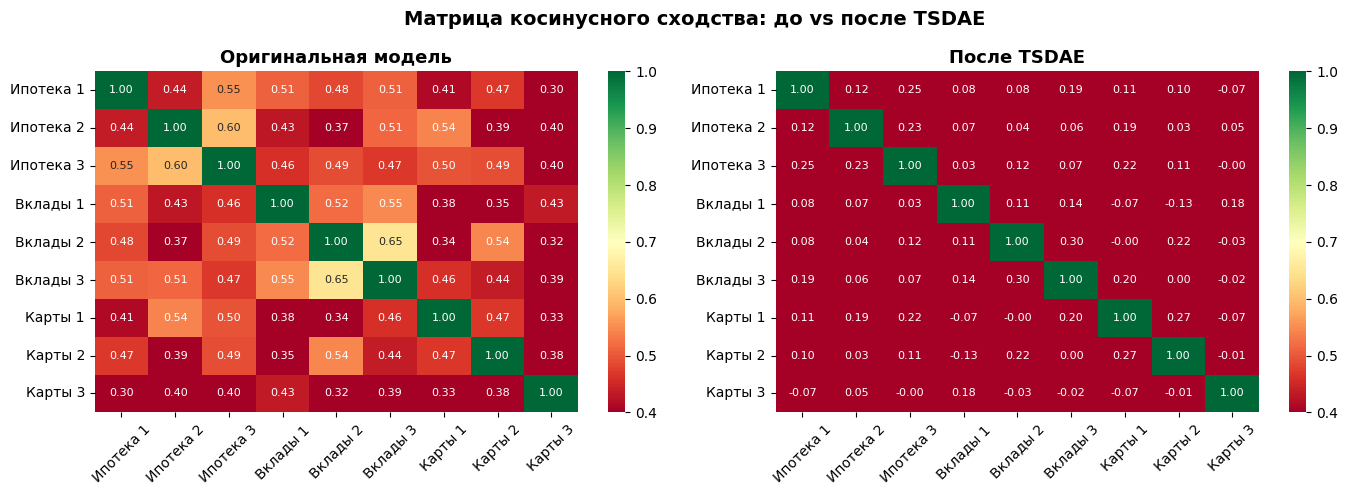

Оригинал    внутри темы: 0.498   между темами: 0.437   разрыв: 0.061
TSDAE       внутри темы: 0.146   между темами: 0.068   разрыв: 0.078


In [13]:
# Берём по 3 чанка из разных тематик для наглядности
sample_texts = [
    # Ипотека
    "Первоначальный взнос по ипотеке составляет не менее 15% от стоимости объекта недвижимости.",
    "Досрочное погашение ипотеки осуществляется без штрафных санкций.",
    "Рефинансирование ипотечного кредита позволяет снизить действующую процентную ставку.",
    # Вклады
    "Система страхования вкладов обеспечивает возмещение средств до 1 400 000 рублей.",
    "Вклад с капитализацией процентов предусматривает начисление процентов на ранее начисленные.",
    "Процентная ставка по вкладу фиксируется на весь срок размещения.",
    # Карты
    "Льготный беспроцентный период по кредитной карте составляет до 55 дней.",
    "Снятие наличных с кредитной карты сопровождается комиссией и начислением процентов.",
    "Технология 3D Secure обеспечивает дополнительную защиту онлайн-платежей.",
]
labels = [
    "Ипотека 1", "Ипотека 2", "Ипотека 3",
    "Вклады 1",  "Вклады 2",  "Вклады 3",
    "Карты 1",   "Карты 2",   "Карты 3",
]

model_orig  = SentenceTransformer(MODEL_NAME)
model_tsdae = SentenceTransformer("../output/stage1_tsdae/final")

emb_orig  = model_orig.encode(sample_texts,  normalize_embeddings=True)
emb_tsdae = model_tsdae.encode(sample_texts, normalize_embeddings=True)

sim_orig  = cosine_similarity(emb_orig)
sim_tsdae = cosine_similarity(emb_tsdae)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
kw = dict(vmin=0.4, vmax=1.0, cmap="RdYlGn", annot=True, fmt=".2f",
          annot_kws={"size": 8}, xticklabels=labels, yticklabels=labels)

sns.heatmap(sim_orig,  ax=axes[0], **kw)
axes[0].set_title("Оригинальная модель", fontsize=13, fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(sim_tsdae, ax=axes[1], **kw)
axes[1].set_title("После TSDAE", fontsize=13, fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Матрица косинусного сходства: до vs после TSDAE",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/stage1_similarity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Среднее сходство внутри темы vs между темами
for name, sim in [("Оригинал", sim_orig), ("TSDAE", sim_tsdae)]:
    intra = np.mean([sim[i,j] for i in range(9) for j in range(9)
                     if i != j and i//3 == j//3])
    inter = np.mean([sim[i,j] for i in range(9) for j in range(9)
                     if i//3 != j//3])
    print(f"{name:10s}  внутри темы: {intra:.3f}   между темами: {inter:.3f}   "
          f"разрыв: {intra-inter:.3f}")

---
# ЭТАП 2 — Supervised Fine-tuning: триплеты (anchor, positive, negative)

Теперь обучаем модель явно различать **релевантные** и **нерелевантные** пары.  
Используем размеченные триплеты из `data_test/stage2_supervised/`.

```
anchor   = пользовательский запрос
positive = правильный ответ-чанк (100% релевантен)
negative = похожий, но неправильный чанк (hard negative из смежной темы)
```

## 2.1 Загрузка триплетов

In [ ]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(".")), "src"))
from data_preparation import Chunk, TripletSampler

# Загружаем корпус из этапа 1
corpus_df = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")

# Создаём Chunk-объекты с назначением doc_id по блокам (~10 чанков = 1 документ).
# В продакшне doc_id и section должны храниться в CSV явно.
GROUP_SIZE = 10
chunks = [
    Chunk(
        text=row["sentence"],
        doc_id=f"doc_{i // GROUP_SIZE:02d}",
        chunk_id=f"chunk_{i:04d}",
    )
    for i, row in corpus_df.iterrows()
]

# Генерируем триплеты: anchor = шаблонный запрос, positive = чанк, negative = BM25-hard
sampler = TripletSampler(chunks, negative_strategy="bm25", seed=42)
all_df = sampler.to_dataframe(strategies=["query_template"], n_per_chunk=1)

# Разбивка 80 / 20
train_df = all_df.sample(frac=0.8, random_state=42).reset_index(drop=True)
eval_df  = all_df.drop(train_df.index).reset_index(drop=True)

print(f"Train : {len(train_df)} триплетов")
print(f"Eval  : {len(eval_df)}  триплетов")
print(f"Колонки: {train_df.columns.tolist()}")


In [15]:
train_df.head(2)

,anchor,positive,negative
0,как диверсифицировать инвестиционный портфель,Диверсификация — распределение средств между р...,Диверсификация депозитного портфеля предполага...
1,что делать при потере кредитной карты,При утере или краже карты необходимо немедленн...,"При утере документов, необходимых для открытия..."


## 2.2 EDA триплетов — реальные примеры

In [16]:
pd.set_option("display.max_colwidth", 90)

print("=" * 100)
print("5 СЛУЧАЙНЫХ ТРИПЛЕТОВ ИЗ TRAIN")
print("=" * 100)
for _, row in train_df.sample(5, random_state=7).iterrows():
    print(f"\n  ANCHOR   : {row['anchor']}")
    print(f"  POSITIVE : {row['positive'][:100]}...")
    print(f"  NEGATIVE : {row['negative'][:100]}...")
    print("  " + "─" * 96)

5 СЛУЧАЙНЫХ ТРИПЛЕТОВ ИЗ TRAIN

  ANCHOR   : как работает система быстрых платежей
  POSITIVE : СБП (Система быстрых платежей) позволяет мгновенно переводить деньги по номеру телефона между клиент...
  NEGATIVE : SWIFT-переводы используются для трансграничных платежей в иностранной валюте. Срок зачисления — 1–5 ...
  ────────────────────────────────────────────────────────────────────────────────────────────────

  ANCHOR   : что такое ИИС и как получить налоговый вычет
  POSITIVE : ИИС (индивидуальный инвестиционный счёт) открывается у брокера или в управляющей компании. Тип А: вы...
  NEGATIVE : НПФ (негосударственный пенсионный фонд) позволяет сформировать накопительную пенсию. Взносы в НПФ та...
  ────────────────────────────────────────────────────────────────────────────────────────────────

  ANCHOR   : что покрывает страховка КАСКО
  POSITIVE : КАСКО покрывает: ущерб от ДТП (включая вину владельца), угон, хищение, пожар, стихийные бедствия, де...
  NEGATIVE : ОСАГО покрывает то

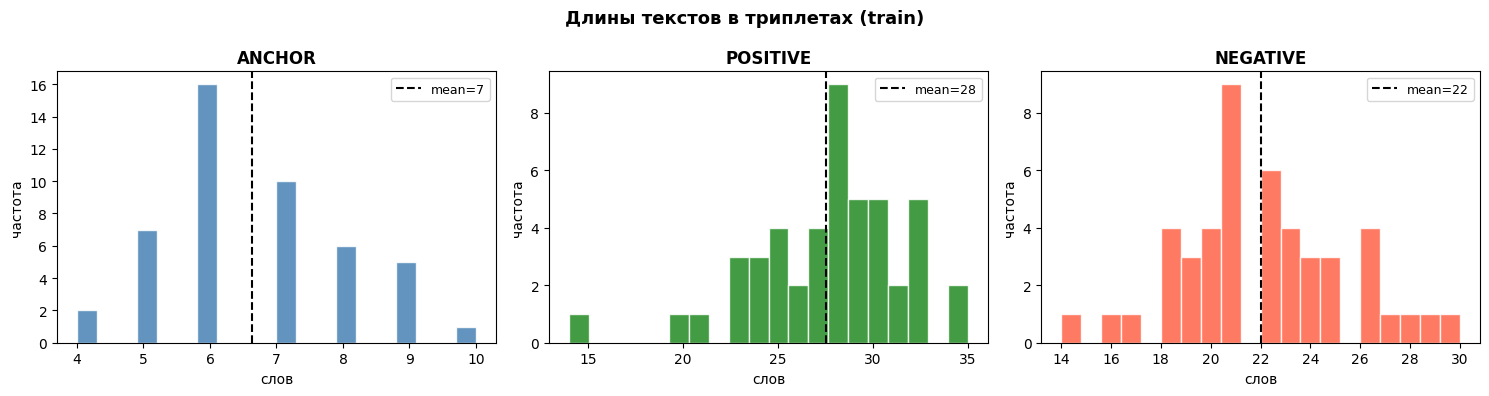

In [17]:
# Статистика длин по каждой роли
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = {"anchor": "steelblue", "positive": "forestgreen", "negative": "tomato"}

for ax, col in zip(axes, ["anchor", "positive", "negative"]):
    lengths = train_df[col].str.split().str.len()
    ax.hist(lengths, bins=20, color=palette[col], edgecolor="white", alpha=0.85)
    ax.axvline(lengths.mean(), color="black", linestyle="--",
               label=f"mean={lengths.mean():.0f}")
    ax.set_title(col.upper(), fontsize=12, fontweight="bold")
    ax.set_xlabel("слов"); ax.set_ylabel("частота")
    ax.legend(fontsize=9)

plt.suptitle("Длины текстов в триплетах (train)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 2.3 Анализ сложности негативов — почему они «трудные»?

Считаем косинусное сходство `sim(anchor, positive)` и `sim(anchor, negative)` на **оригинальной** модели.  
Хорошо подобранный hard negative: его сходство с anchor лишь немного ниже, чем у positive.  
Если разрыв маленький — модели трудно их различить, и она реально учится.

In [18]:
print("Вычисляем сходства с оригинальной моделью...")

anchors   = train_df["anchor"].tolist()
positives = train_df["positive"].tolist()
negatives = train_df["negative"].tolist()

emb_a = model_orig.encode(anchors,   normalize_embeddings=True, show_progress_bar=True)
emb_p = model_orig.encode(positives, normalize_embeddings=True, show_progress_bar=True)
emb_n = model_orig.encode(negatives, normalize_embeddings=True, show_progress_bar=True)

sim_pos = (emb_a * emb_p).sum(axis=1)   # поэлементное скалярное произведение
sim_neg = (emb_a * emb_n).sum(axis=1)
gap     = sim_pos - sim_neg

train_df["sim_pos"] = sim_pos
train_df["sim_neg"] = sim_neg
train_df["gap"]     = gap

print(f"\nsim(anchor, positive)  mean={sim_pos.mean():.3f}  min={sim_pos.min():.3f}  max={sim_pos.max():.3f}")
print(f"sim(anchor, negative)  mean={sim_neg.mean():.3f}  min={sim_neg.min():.3f}  max={sim_neg.max():.3f}")
print(f"gap (pos - neg)        mean={gap.mean():.3f}  min={gap.min():.3f}  max={gap.max():.3f}")
print(f"\nТриплетов где gap < 0.1 (очень трудные): {(gap < 0.1).sum()} ({(gap < 0.1).mean()*100:.0f}%)")
print(f"Триплетов где gap < 0   (false negatives?): {(gap < 0).sum()}")

Вычисляем сходства с оригинальной моделью...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]


sim(anchor, positive)  mean=0.714  min=0.621  max=0.816
sim(anchor, negative)  mean=0.519  min=0.275  max=0.774
gap (pos - neg)        mean=0.195  min=-0.031  max=0.407

Триплетов где gap < 0.1 (очень трудные): 11 (23%)
Триплетов где gap < 0   (false negatives?): 1


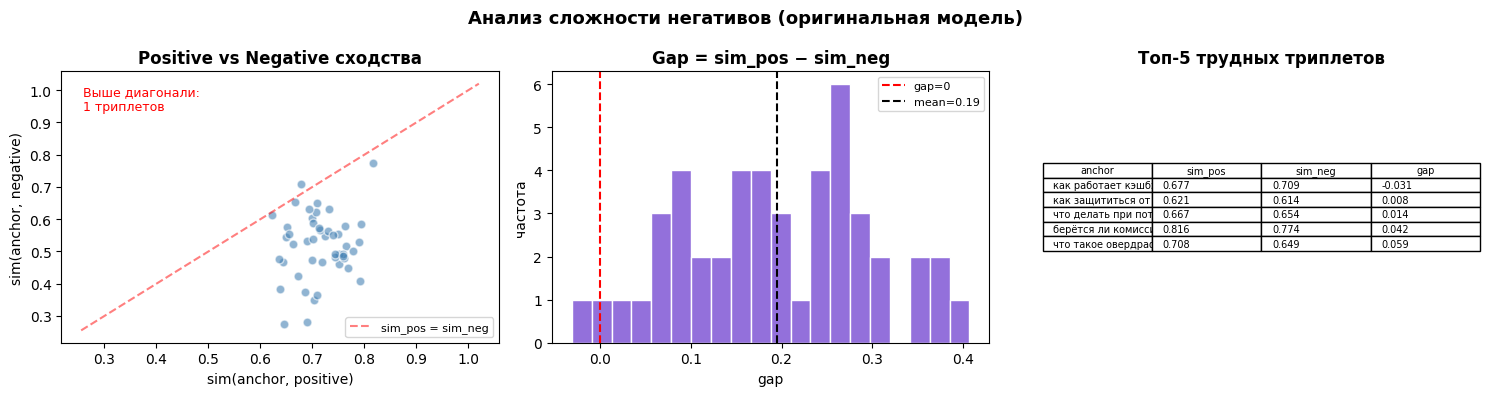

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Scatter: sim_pos vs sim_neg
axes[0].scatter(sim_pos, sim_neg, alpha=0.6, color="steelblue", s=40, edgecolors="white")
lim = [min(sim_pos.min(), sim_neg.min()) - 0.02, 1.02]
axes[0].plot(lim, lim, "r--", alpha=0.5, label="sim_pos = sim_neg")
axes[0].set_xlabel("sim(anchor, positive)"); axes[0].set_ylabel("sim(anchor, negative)")
axes[0].set_title("Positive vs Negative сходства", fontweight="bold")
axes[0].legend(fontsize=8)
# Точки выше диагонали — где модели трудно (negative > positive)
hard = (sim_neg > sim_pos).sum()
axes[0].text(0.05, 0.95, f"Выше диагонали:\n{hard} триплетов",
             transform=axes[0].transAxes, va="top", fontsize=9, color="red")

# Распределение gap
axes[1].hist(gap, bins=20, color="mediumpurple", edgecolor="white")
axes[1].axvline(0,          color="red",   linestyle="--", label="gap=0")
axes[1].axvline(gap.mean(), color="black", linestyle="--", label=f"mean={gap.mean():.2f}")
axes[1].set_title("Gap = sim_pos − sim_neg", fontweight="bold")
axes[1].set_xlabel("gap"); axes[1].set_ylabel("частота")
axes[1].legend(fontsize=8)

# Топ-5 самых трудных триплетов
hardest = train_df.nsmallest(5, "gap")[["anchor", "sim_pos", "sim_neg", "gap"]]
axes[2].axis("off")
tbl = axes[2].table(
    cellText=[
        [r["anchor"][:35]+"...", f"{r['sim_pos']:.3f}", f"{r['sim_neg']:.3f}", f"{r['gap']:.3f}"]
        for _, r in hardest.iterrows()
    ],
    colLabels=["anchor", "sim_pos", "sim_neg", "gap"],
    loc="center", cellLoc="left",
)
tbl.auto_set_font_size(False); tbl.set_fontsize(7)
axes[2].set_title("Топ-5 трудных триплетов", fontweight="bold")

plt.suptitle("Анализ сложности негативов (оригинальная модель)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/stage2_negative_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Показываем самые трудные триплеты вербально
print("TOP-3 ТРУДНЫХ ТРИПЛЕТА (gap наименьший — модели сложнее всего их различить):\n")
for _, row in train_df.nsmallest(3, "gap").iterrows():
    print(f"  ANCHOR   : {row['anchor']}")
    print(f"  POSITIVE : {row['positive'][:110]}")
    print(f"             sim={row['sim_pos']:.3f}")
    print(f"  NEGATIVE : {row['negative'][:110]}")
    print(f"             sim={row['sim_neg']:.3f}  |  gap={row['gap']:.3f}")
    print("  " + "─" * 100)

TOP-3 ТРУДНЫХ ТРИПЛЕТА (gap наименьший — модели сложнее всего их различить):

  ANCHOR   : как работает кэшбэк по кредитной карте
  POSITIVE : Кэшбэк начисляется на счёт бонусов или рублями в размере от 1% до 10% от суммы покупок. Повышенный кэшбэк дейс
             sim=0.677
  NEGATIVE : Программа лояльности по дебетовой карте начисляет кэшбэк рублями или бонусными баллами за безналичные покупки.
             sim=0.709  |  gap=-0.031
  ────────────────────────────────────────────────────────────────────────────────────────────────────
  ANCHOR   : как защититься от мошенничества с картой при онлайн-платежах
  POSITIVE : Технология 3D Secure требует подтверждения каждой онлайн-покупки одноразовым SMS-кодом. Для дополнительной защ
             sim=0.621
  NEGATIVE : Двухфакторная аутентификация в интернет-банке требует ввода пароля и подтверждения входа через мобильное прило
             sim=0.614  |  gap=0.008
  ──────────────────────────────────────────────────────────────────────────

## 2.4 Эксперимент А: TripletLoss

**Формула:** `L = max(0, d(a,p) − d(a,n) + margin)`

Явно обучаем: positive должен быть ближе к anchor, чем negative, с зазором `margin`.

In [21]:
if DEVICE == "cpu":
    cfg_triplet = make_cpu_config(
        loss_type=LossType.TRIPLET,
        num_epochs=2,
        output_dir="../output/stage2_triplet",
    )
else:
    cfg_triplet = make_gpu_config(
        loss_type=LossType.TRIPLET,
        num_epochs=3,
        output_dir="../output/stage2_triplet",
    )
cfg_triplet.triplet_margin = 0.5

print(f"Loss     : {cfg_triplet.loss_type}")
print(f"Margin   : {cfg_triplet.triplet_margin}")
print(f"Epochs   : {cfg_triplet.num_epochs}")
print(f"Batch    : {cfg_triplet.batch_size} (eff: {cfg_triplet.batch_size * cfg_triplet.gradient_accumulation_steps})")
print(f"Device   : {DEVICE}")

Loss     : LossType.TRIPLET
Margin   : 0.5
Epochs   : 3
Batch    : 32 (eff: 32)
Device   : cuda


In [22]:
trainer_triplet = EmbeddingTrainer(cfg_triplet)

2026-03-24 18:16:43,187 | INFO | Устройство: cuda
2026-03-24 18:16:43,188 | INFO | GPU: включён bf16
2026-03-24 18:16:43,188 | INFO | Загрузка модели: deepvk/USER-bge-m3
2026-03-24 18:16:43,194 | INFO | Load pretrained SentenceTransformer: deepvk/USER-bge-m3
2026-03-24 18:16:43,465 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:16:43,500 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/modules.json "HTTP/1.1 200 OK"
2026-03-24 18:16:43,661 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:16:43,697 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config_sentence_transformers.json "HTTP/1.1 200 OK"
2026-03-2

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

2026-03-24 18:16:45,375 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:16:45,413 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/config.json "HTTP/1.1 200 OK"
2026-03-24 18:16:45,576 | INFO | HTTP Request: HEAD https://huggingface.co/deepvk/USER-bge-m3/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-24 18:16:45,612 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/deepvk/USER-bge-m3/0cc6cfe48e260fb0474c753087a69369e88709ae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-03-24 18:16:45,781 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge-m3/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-03-24 18:16:46,166 | INFO | HTTP Request: GET https://huggingface.co/api/models/deepvk/USER-bge

In [23]:
trainer_triplet.train(train_df, eval_df)

2026-03-24 18:16:55,356 | INFO | Подготовка датасета: 47 обучающих строк, loss=LossType.TRIPLET
2026-03-24 18:16:55,366 | WARNING | The `warmup_ratio` argument is deprecated in Transformers v5+, and will also be removed from Sentence Transformers once support for Transformers v4 is dropped. Since you're using Transformers v5+, please use `warmup_steps` (as a float) to specify the warmup ratio instead.


AttributeError: 'str' object has no attribute '__name__'

In [ ]:
trainer_triplet.save_model("../output/stage2_triplet/final")
print("TripletLoss обучение завершено.")

## 2.5 Эксперимент Б: MNRL (рекомендованный)

**Формула:** `L = -log( exp(sim(aᵢ, pᵢ)/τ) / Σⱼ exp(sim(aᵢ, pⱼ)/τ) )`

In-batch negatives: при `batch_size=B` каждый запрос получает `B-1` негативов бесплатно.  
Колонка `negative` из CSV добавляется как дополнительный hard negative поверх in-batch.

In [ ]:
# Визуализируем идею in-batch negatives
batch_sizes = [4, 8, 16, 32, 64]
negatives_per_query = [b - 1 for b in batch_sizes]

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(batch_sizes, negatives_per_query, color="steelblue",
              width=10, edgecolor="white")
ax.bar_label(bars, labels=[f"{n} neg" for n in negatives_per_query],
             padding=3, fontsize=9)
ax.set_xlabel("batch_size"); ax.set_ylabel("негативов на запрос")
ax.set_title("MNRL: количество in-batch негативов", fontweight="bold")
ax.set_xticks(batch_sizes)
cfg_b = cfg_triplet.batch_size
ax.axvline(cfg_b, color="tomato", linestyle="--", label=f"наш batch={cfg_b}")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
if DEVICE == "cpu":
    cfg_mnrl = make_cpu_config(
        loss_type=LossType.MNRL,
        num_epochs=2,
        output_dir="../output/stage2_mnrl",
    )
else:
    cfg_mnrl = make_gpu_config(
        loss_type=LossType.MNRL,
        num_epochs=3,
        output_dir="../output/stage2_mnrl",
    )
cfg_mnrl.temperature = 0.05

print(f"Loss        : {cfg_mnrl.loss_type}")
print(f"Temperature : {cfg_mnrl.temperature}  (scale = {1/cfg_mnrl.temperature:.0f})")
print(f"Epochs      : {cfg_mnrl.num_epochs}")
print(f"Batch       : {cfg_mnrl.batch_size}")
print(f"Device      : {DEVICE}")

In [ ]:
trainer_mnrl = EmbeddingTrainer(cfg_mnrl)
trainer_mnrl.train(train_df, eval_df)
trainer_mnrl.save_model("../output/stage2_mnrl/final")
print("MNRL обучение завершено.")

---
# Оценка качества: сравниваем все модели

Строим retrieval-тест из наших триплетов:  
- `queries`  = все anchors  
- `corpus`   = все positives + все negatives  
- `qrels`    = anchor → [его positive]

## 3.1 Формируем eval set

In [ ]:
# Объединяем train + eval для построения корпуса оценки
all_triplets_df = pd.concat([train_df, eval_df], ignore_index=True)

queries, corpus, qrels = build_evaluation_set(
    triplets_df=all_triplets_df,
    n_queries=len(all_triplets_df),
    seed=42,
)

evaluator = RetrievalEvaluator(
    queries=queries,
    corpus=corpus,
    qrels=qrels,
    ks=(1, 3, 5, 10),
)

print(f"Запросов : {len(queries)}")
print(f"Корпус   : {len(corpus)} документов")

## 3.2 Оцениваем все 4 модели

In [ ]:
models_to_eval = {
    "baseline":      MODEL_NAME,
    "tsdae":         "../output/stage1_tsdae/final",
    "triplet":       "../output/stage2_triplet/final",
    "mnrl":          "../output/stage2_mnrl/final",
}

results = {}
for alias, path in models_to_eval.items():
    print(f"\nОцениваем: {alias} ({path})")
    results[alias] = evaluator.evaluate(path, batch_size=32)

print("\nОценка завершена.")

In [ ]:
metric_cols = ["Recall@1", "Recall@3", "Recall@5", "Recall@10",
               "MRR@10", "NDCG@10", "MAP@10"]

comparison_df = pd.DataFrame(
    {alias: m.to_dict() for alias, m in results.items()}
).T[metric_cols]

# Прирост относительно baseline
delta_df = comparison_df.subtract(comparison_df.loc["baseline"]).round(4)

print("Абсолютные значения метрик:")
display(comparison_df.style
    .highlight_max(axis=0, color="#c6efce")
    .highlight_min(axis=0, color="#ffc7ce")
    .format("{:.4f}"))

print("\nПрирост относительно baseline (Δ):")
display(delta_df.drop(index="baseline").style
    .background_gradient(cmap="RdYlGn", axis=None, vmin=-0.15, vmax=0.15)
    .format("{:+.4f}"))

## 3.3 Визуализация

In [ ]:
colors = ["#4C72B0", "#8172B2", "#DD8452", "#55A868"]
aliases = comparison_df.index.tolist()

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── График 1: Recall@k ────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
recall_cols = ["Recall@1", "Recall@3", "Recall@5", "Recall@10"]
x = np.arange(len(recall_cols)); w = 0.18
for i, (alias, color) in enumerate(zip(aliases, colors)):
    vals = comparison_df.loc[alias, recall_cols].values
    bars = ax1.bar(x + i*w, vals, w, label=alias, color=color, edgecolor="white")
    ax1.bar_label(bars, fmt="%.2f", fontsize=6, padding=1)
ax1.set_xticks(x + w*1.5); ax1.set_xticklabels([c.replace("Recall@","@") for c in recall_cols])
ax1.set_ylim(0, 1.2); ax1.set_title("Recall@k", fontweight="bold")
ax1.legend(fontsize=8); ax1.grid(axis="y", alpha=0.3)

# ── График 2: MRR / NDCG / MAP ────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
other_cols = ["MRR@10", "NDCG@10", "MAP@10"]
x2 = np.arange(len(other_cols))
for i, (alias, color) in enumerate(zip(aliases, colors)):
    vals = comparison_df.loc[alias, other_cols].values
    bars = ax2.bar(x2 + i*w, vals, w, label=alias, color=color, edgecolor="white")
    ax2.bar_label(bars, fmt="%.2f", fontsize=6, padding=1)
ax2.set_xticks(x2 + w*1.5); ax2.set_xticklabels(other_cols)
ax2.set_ylim(0, 1.2); ax2.set_title("MRR@10 / NDCG@10 / MAP@10", fontweight="bold")
ax2.legend(fontsize=8); ax2.grid(axis="y", alpha=0.3)

# ── График 3: Прирост Recall@k (Δ) ───────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
delta_recall = delta_df.drop(index="baseline")[recall_cols]
delta_recall.T.plot(kind="bar", ax=ax3, color=colors[1:], edgecolor="white", width=0.65)
ax3.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax3.set_title("ΔRecall@k относительно baseline", fontweight="bold")
ax3.set_xlabel(""); ax3.set_ylabel("Δ")
ax3.tick_params(axis="x", rotation=0)
ax3.legend(fontsize=8); ax3.grid(axis="y", alpha=0.3)

# ── График 4: Radar ───────────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1], polar=True)
radar_cols = ["Recall@1", "Recall@5", "Recall@10", "MRR@10", "NDCG@10"]
N = len(radar_cols)
angles = [n / N * 2 * np.pi for n in range(N)] + [0]
for alias, color in zip(aliases, colors):
    vals = comparison_df.loc[alias, radar_cols].tolist()
    vals += [vals[0]]
    ax4.plot(angles, vals, linewidth=2, color=color, label=alias)
    ax4.fill(angles, vals, alpha=0.08, color=color)
ax4.set_xticks(angles[:-1]); ax4.set_xticklabels(radar_cols, fontsize=8)
ax4.set_ylim(0, 1); ax4.set_title("Профиль качества", fontweight="bold", pad=15)
ax4.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=8)

plt.suptitle("Сравнение моделей: baseline → TSDAE → TripletLoss → MNRL",
             fontsize=14, fontweight="bold", y=1.01)
plt.savefig("../output/full_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.4 Качественный анализ: что именно изменилось в retrieval

In [ ]:
# Строим корпус из stage1 (чанки) для демонстрации живого поиска
corpus_df_reload = pd.read_csv(DATA / "stage1_tsdae" / "corpus.csv")
corpus_texts = corpus_df_reload["sentence"].tolist()

# Тестовые запросы из eval триплетов
test_queries = eval_df["anchor"].head(4).tolist()
ground_truth = eval_df["positive"].head(4).tolist()

def search(model_or_path, queries, corpus, top_k=3):
    if isinstance(model_or_path, str):
        m = SentenceTransformer(model_or_path)
    else:
        m = model_or_path
    c_emb = m.encode(corpus, normalize_embeddings=True, show_progress_bar=False)
    results = []
    for q in queries:
        q_emb = m.encode([q], normalize_embeddings=True)
        sims  = (q_emb @ c_emb.T)[0]
        top   = np.argsort(sims)[::-1][:top_k]
        results.append([(corpus[i], float(sims[i])) for i in top])
    return results

res_baseline = search(MODEL_NAME,                        test_queries, corpus_texts)
res_mnrl     = search("../output/stage2_mnrl/final",     test_queries, corpus_texts)

print("=" * 100)
for i, (query, gt) in enumerate(zip(test_queries, ground_truth)):
    print(f"\nЗАПРОС: {query}")
    print(f"ЭТАЛОН: {gt[:95]}...\n")

    print(f"  {'BASELINE':^46}  {'MNRL (дообученная)':^46}")
    print(f"  {'─'*46}  {'─'*46}")
    for rank, (b, m) in enumerate(zip(res_baseline[i], res_mnrl[i]), 1):
        mark_b = "✓" if gt[:40] in b[0] else " "
        mark_m = "✓" if gt[:40] in m[0] else " "
        print(f"  [{rank}]{mark_b} ({b[1]:.3f}) {b[0][:38]:<38}  [{rank}]{mark_m} ({m[1]:.3f}) {m[0][:38]:<38}")
    print("=" * 100)

## 3.5 Как изменились сходства после обучения (gap анализ)

In [ ]:
model_mnrl = SentenceTransformer("../output/stage2_mnrl/final")

emb_a_ft = model_mnrl.encode(anchors,   normalize_embeddings=True)
emb_p_ft = model_mnrl.encode(positives, normalize_embeddings=True)
emb_n_ft = model_mnrl.encode(negatives, normalize_embeddings=True)

sim_pos_ft = (emb_a_ft * emb_p_ft).sum(axis=1)
sim_neg_ft = (emb_a_ft * emb_n_ft).sum(axis=1)
gap_ft     = sim_pos_ft - sim_neg_ft

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (gap_vals, label, color) in zip(axes, [
    (gap,    "Baseline",      "steelblue"),
    (gap_ft, "MNRL (дообученная)", "forestgreen"),
]):
    ax.hist(gap_vals, bins=20, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(0,              color="red",   linestyle="--", label="gap=0")
    ax.axvline(gap_vals.mean(),color="black", linestyle="--",
               label=f"mean={gap_vals.mean():.3f}")
    ax.set_title(f"Gap распределение — {label}", fontweight="bold")
    ax.set_xlabel("gap = sim_pos − sim_neg")
    ax.set_ylabel("частота")
    ax.legend(fontsize=9)

plt.suptitle("Gap до и после дообучения (чем правее — тем лучше)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../output/gap_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Baseline  gap: mean={gap.mean():.3f}  |  gap<0: {(gap<0).sum()} триплетов")
print(f"MNRL      gap: mean={gap_ft.mean():.3f}  |  gap<0: {(gap_ft<0).sum()} триплетов")

---
## Итоги

| Этап | Данные | Что обучилось | Когда использовать |
|------|--------|---------------|--------------------|
| **TSDAE** | `stage1_tsdae/corpus.csv` (75 чанков, без разметки) | Доменная лексика | Всегда — даже без лейблов |
| **TripletLoss** | `stage2_supervised/train.csv` (47 триплетов) | Явный зазор pos/neg | Малые данные, интерпретируемость |
| **MNRL** | `stage2_supervised/train.csv` (47 триплетов) | In-batch negatives | **Рекомендован** — лучшее качество |

**Лучшая практика для банка:**  
1. TSDAE на всех доступных чанках → сохраняем модель  
2. MNRL на триплетах (anchor=запрос, positive=чанк, negative=BM25-hard из смежной темы)  
3. После 1-й эпохи заменить BM25-негативы на embedding-hard (ANCE)